# 14 · Crystallization

Most solid products - salts, sugars, pharmaceuticals - are made by crystallisation, which purifies and
shapes at the same time. The yield comes from solubility; the crystal size distribution, which decides
filtration, drying, flow and dissolution, comes from the competition between nucleation and growth. This
notebook computes yields from a solubility table, follows supersaturation in the metastable zone, and applies
the MSMPR population balance to extract kinetics from a measured size distribution and to design for a
target crystal size.

**What you will learn**
- compute cooling and evaporative yields, including hydrates
- reason about supersaturation and the metastable zone
- extract growth and nucleation kinetics from an MSMPR size distribution
- design an MSMPR for a target size

**Before you start:** notebook 00  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import crystallization as cr
from engsep import datasets
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Solubility and yield

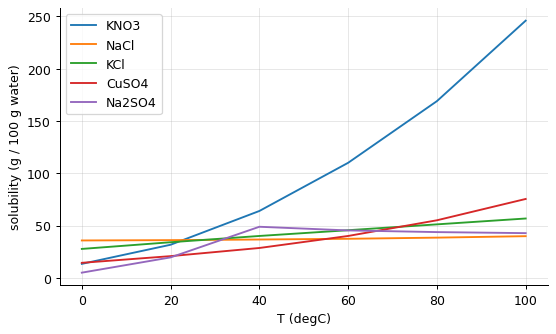

cooling 1000 kg of saturated KNO3 solution from 80 to 20 degC: 511 kg of crystals (81% of the solute)
cooling 1000 kg of saturated NaCl solution from 80 to 20 degC: 17 kg of crystals (6% of the solute)
evaporating 300 kg of water from the NaCl solution at 80 degC instead: 115 kg of crystals


In [2]:
T = np.linspace(0, 100, 101)
fig, ax = plt.subplots()
for salt in ("KNO3", "NaCl", "KCl", "CuSO4", "Na2SO4"):
    ax.plot(T, cr.solubility(salt, T), label=salt)
ax.set(xlabel="T (degC)", ylabel="solubility (g / 100 g water)"); ax.legend(); plt.show()
for salt in ("KNO3", "NaCl"):
    cy = cr.cooling_yield(salt, 1000.0, 80.0, 20.0)
    print(f"cooling 1000 kg of saturated {salt} solution from 80 to 20 degC: {cy['crystals_kg']:.0f} kg of crystals ({cy['yield_fraction']:.0%} of the solute)")
cy_e = cr.cooling_yield("NaCl", 1000.0, 80.0, 80.0, evaporated_water_kg=300.0)
print(f"evaporating 300 kg of water from the NaCl solution at 80 degC instead: {cy_e['crystals_kg']:.0f} kg of crystals")

Potassium nitrate's solubility rises fivefold between 20 and 80 degC, so cooling crystallisation recovers
80 % of it; sodium chloride's barely changes, so salt is crystallised by evaporation instead. The choice
between cooling, evaporation and antisolvent crystallisation is read off the solubility curve.

## Hydrates

In [3]:
h = 5 * 18.02 / 159.6                                                # kg of water of crystallisation per kg CuSO4 in CuSO4.5H2O
cy = cr.cooling_yield("CuSO4", 1000.0, 80.0, 20.0, hydrate_water_ratio=h)
print(f"CuSO4.5H2O from 1000 kg of solution saturated at 80 degC, cooled to 20: {cy['crystals_kg']:.0f} kg of pentahydrate ({cy['anhydrous_kg']:.0f} kg CuSO4), yield {cy['yield_fraction']:.0%}")

CuSO4.5H2O from 1000 kg of solution saturated at 80 degC, cooled to 20: 392 kg of pentahydrate (251 kg CuSO4), yield 71%


When the crystal takes water with it, the mother liquor loses solvent as well as solute and the balance must
account for both; the yield of the hydrate is higher than the anhydrous solubility difference suggests,
and the crystals weigh more. Blue vitriol is a quarter water by mass.

## Supersaturation and the metastable zone

In [4]:
c_star = float(cr.solubility("KNO3", 40.0))
for c in (c_star * 1.02, c_star * 1.05, c_star * 1.15):
    s = cr.supersaturation(c, c_star)
    print(f"c = {c:.1f} g/100 g at 40 degC: relative supersaturation {s['relative']:.2f} -> " + ("growth only (metastable)" if s["relative"] < 0.08 else "spontaneous nucleation likely"))

c = 65.2 g/100 g at 40 degC: relative supersaturation 0.02 -> growth only (metastable)
c = 67.1 g/100 g at 40 degC: relative supersaturation 0.05 -> growth only (metastable)
c = 73.5 g/100 g at 40 degC: relative supersaturation 0.15 -> spontaneous nucleation likely


Between saturation and the metastable limit crystals grow but do not spontaneously nucleate; beyond it a
shower of nuclei appears and the product is fine dust. Industrial crystallisers keep supersaturation inside
the zone - a few percent - by controlling cooling or evaporation rate, and seed to avoid waiting for
nucleation.

## The MSMPR crystalliser and its size distribution

from the population density plot: G = 8.00 nm/s, n0 = 2.02e+17 1/(m3 m), nucleation rate B0 = 1.62e+09 1/(m3 s)   (generated with G = 8 nm/s, n0 = 2e17)


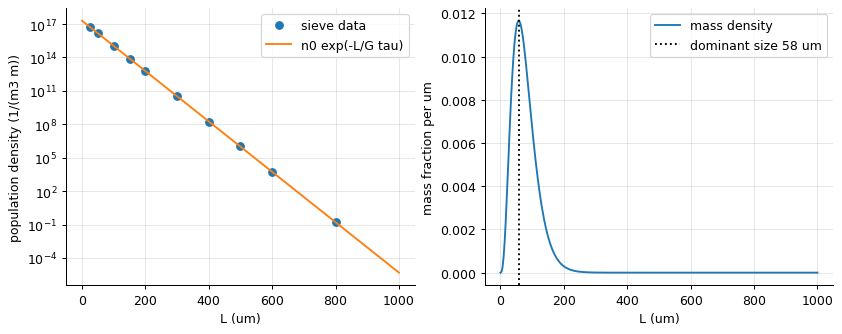

In [5]:
d = pd.read_csv(datasets.path("csd_msmpr.csv"), comment="#")
fit = cr.msmpr_from_csd(d.L_m, d.n_per_m3_m, tau=2400.0)
print(f"from the population density plot: G = {fit['G']*1e9:.2f} nm/s, n0 = {fit['n0']:.2e} 1/(m3 m), nucleation rate B0 = {fit['B0']:.2e} 1/(m3 s)   (generated with G = 8 nm/s, n0 = 2e17)")
L = np.linspace(0, 1e-3, 300)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(d.L_m * 1e6, d.n_per_m3_m, "o", label="sieve data"); ax[0].semilogy(L * 1e6, cr.msmpr_population(L, fit["n0"], fit["G"], 2400.0), label="n0 exp(-L/G tau)"); ax[0].set(xlabel="L (um)", ylabel="population density (1/(m3 m))"); ax[0].legend()
ax[1].plot(L * 1e6, cr.msmpr_mass_distribution(L, fit["G"], 2400.0) * 1e-6, label="mass density"); ax[1].axvline(cr.msmpr_dominant_size(fit["G"], 2400.0) * 1e6, color="k", ls=":", label=f"dominant size {cr.msmpr_dominant_size(fit['G'], 2400.0)*1e6:.0f} um"); ax[1].set(xlabel="L (um)", ylabel="mass fraction per um"); ax[1].legend(); plt.show()

In a mixed-suspension mixed-product-removal crystalliser the population density is exponential in size,
$n = n^0 e^{-L/G\tau}$: the slope of the semi-log plot gives the growth rate, the intercept the nuclei
density, and their product the nucleation rate. Two numbers from one sieve analysis - and the mass
distribution peaks at $3G\tau$, the dominant size that customers specify.

## Designing for a crystal size

In [6]:
M_T = 200.0                                                          # kg/m3 magma density
for L_D in (200e-6, 400e-6, 800e-6):
    des = cr.msmpr_design(M_T, L_D, fit["G"])
    print(f"dominant size {L_D*1e6:.0f} um needs tau = {des['tau']/60:.0f} min at G = {fit['G']*1e9:.1f} nm/s, with a nucleation rate of {des['B0']:.2e} 1/(m3 s)")
print("\ndoubling the crystal size needs double the residence time and cuts the allowable nucleation rate sixteenfold: nucleation control (seeding, gentle stirring) is the whole game")

dominant size 200 um needs tau = 139 min at G = 8.0 nm/s, with a nucleation rate of 1.29e+07 1/(m3 s)
dominant size 400 um needs tau = 278 min at G = 8.0 nm/s, with a nucleation rate of 8.06e+05 1/(m3 s)
dominant size 800 um needs tau = 556 min at G = 8.0 nm/s, with a nucleation rate of 5.04e+04 1/(m3 s)

doubling the crystal size needs double the residence time and cuts the allowable nucleation rate sixteenfold: nucleation control (seeding, gentle stirring) is the whole game


At fixed growth rate the dominant size is proportional to residence time, but the magma density constrains
the nuclei: $n^0 \propto M_T/(G\tau)^4$. Bigger crystals need a longer, gentler crystalliser with far fewer
nuclei - which is why fines destruction and classified product removal exist, and why the population balance
is the designer's tool rather than the yield alone.

## Inside the algorithm: the population-density slope

In [7]:
slope_, intercept_ = np.polyfit(d.L_m, np.log(d.n_per_m3_m), 1)
print(f"by hand: G = {-1 / (slope_ * 2400.0):.6g} m/s, n0 = {np.exp(intercept_):.6g}; library: {fit['G']:.6g}, {fit['n0']:.6g}")

by hand: G = 7.99936e-09 m/s, n0 = 2.02271e+17; library: 7.99936e-09, 2.02271e+17


## Exercises
1. Sodium sulphate has a solubility maximum near 32 degC (the decahydrate-anhydrous transition). Using the table, find the temperature range over which *cooling* a saturated solution gives crystals and the range over which *heating* does. Which salt is best crystallised by evaporation at 80 degC?
2. The MSMPR data are re-sieved with a coarser set (drop every other size). Refit G and n0 and estimate the uncertainty of the dominant size; then compute how much the residence time must change to shift the dominant size by 20 %.
3. **Implement it yourself:** compute the third moment of the measured population density by trapezoidal integration and compare the magma density it implies (k_v = pi/6, rho_c = 2660 kg/m3) with the closed-form 6 n0 (G tau)^4.